In [61]:
# Import pandas for reading and manipulating the dataset
import pandas as pd

# Import re for performing text cleaning using regular expressions
import re

# Import NLTK for natural language text preprocessing
import nltk

# Import the English stopwords list from NLTK
from nltk.corpus import stopwords

# Import matplotlib for creating visualizations
import matplotlib.pyplot as plt

# Import seaborn for statistical visualizations
import seaborn as sns

# Import Counter for finding the most frequently occurring words
from collections import Counter

# Import WordCloud for generating word cloud visualizations
from wordcloud import WordCloud


# TfidfVectorizer converts text into numerical TF IDF features
from sklearn.feature_extraction.text import TfidfVectorizer

# train_test_split is used to divide the dataset into training and testing data
from sklearn.model_selection import train_test_split

# Logistic Regression is a classification algorithm
from sklearn.linear_model import LogisticRegression

# LinearSVC is a Support Vector Machine classification algorithm
from sklearn.svm import LinearSVC

# Import cross validation function
from sklearn.model_selection import cross_val_score, StratifiedKFold

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Data Cleaning

In [3]:
# Load the English stopwords provided by NLTK
stop_words = set(stopwords.words('english'))

# Display a few stopwords to verify that they were loaded
print(list(stop_words)[:20])

['all', "i'm", 'were', 'too', 'they', "it'd", 'll', 'no', 'which', 'yourself', 'y', 'nor', 'over', "won't", 't', 'won', 'myself', 'hadn', 'o', 'are']


In [5]:
# Load the Amazon reviews TSV file
df = pd.read_csv(
    'amazonreviews.tsv',
    sep='\t'
)

# Display the first five rows
df.head()

,label,review
0,pos,Stuning even for the non-gamer: This sound tra...
1,pos,The best soundtrack ever to anything.: I'm rea...
2,pos,Amazing!: This soundtrack is my favorite music...
3,pos,Excellent Soundtrack: I truly like this soundt...
4,pos,"Remember, Pull Your Jaw Off The Floor After He..."


In [6]:
# Display the number of rows and columns
print("Dataset Shape:", df.shape)

# Display the column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display information about the columns
print("\nDataset Information:")
df.info()

Dataset Shape: (10000, 2)

Column Names:
['label', 'review']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   label   10000 non-null  object
 1   review  10000 non-null  object
dtypes: object(2)
memory usage: 156.4+ KB


In [7]:
# Count the number of missing values in every column
missing_values = df.isnull().sum()

# Display the missing value count
print("Missing Values:")
print(missing_values)

Missing Values:
label     0
review    0
dtype: int64


In [9]:
# Remove rows where the review is missing
# This step does not remove anything from the current dataset
# because the uploaded dataset contains no missing reviews
df = df.dropna(subset=['review'])

# Reset the row index after removing missing values
df = df.reset_index(drop=True)

# Display the updated shape
print("Shape after handling missing reviews:", df.shape)

Shape after handling missing reviews: (10000, 2)


In [10]:
# Count completely duplicated rows
duplicate_rows = df.duplicated().sum()

# Display the number of duplicate rows
print("Number of duplicate rows:", duplicate_rows)

Number of duplicate rows: 0


In [11]:
# Remove duplicate rows from the dataset
# Since there are currently no duplicates, the dataset size remains unchanged
df = df.drop_duplicates()

# Reset the index after removing duplicates
df = df.reset_index(drop=True)

# Display the new dataset shape
print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (10000, 2)


In [12]:
# Display the unique sentiment labels
print("Unique Labels:")
print(df['label'].unique())

# Count the number of reviews belonging to each sentiment
print("\nSentiment Counts:")
print(df['label'].value_counts())

Unique Labels:
['pos' 'neg']

Sentiment Counts:
label
neg    5097
pos    4903
Name: count, dtype: int64


In [13]:
# Create a function for cleaning customer reviews
def clean_text(text):

    # Convert the review to a string
    # This makes the function safer if unexpected data types are present
    text = str(text)

    # Convert all characters to lowercase
    # Example:
    # "Excellent Product" becomes "excellent product"
    text = text.lower()

    # Remove HTML tags if they are present
    # Example:
    # "<br>" is removed from the review
    text = re.sub(r'<.*?>', ' ', text)

    # Remove punctuation and special characters
    # Keep only lowercase English letters and spaces
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Split the review into individual words
    words = text.split()

    # Remove common English stopwords
    # Words such as "the", "is", "and" are removed
    words = [
        word
        for word in words
        if word not in stop_words
    ]

    # Join the remaining words back into a single sentence
    cleaned_text = ' '.join(words)

    # Return the cleaned review
    return cleaned_text

In [14]:
# Apply the cleaning function to every review
df['cleaned_review'] = df['review'].apply(clean_text)

# Display the original and cleaned reviews
df[['review', 'cleaned_review']].head()

,review,cleaned_review
0,Stuning even for the non-gamer: This sound tra...,stuning even non gamer sound track beautiful p...
1,The best soundtrack ever to anything.: I'm rea...,best soundtrack ever anything reading lot revi...
2,Amazing!: This soundtrack is my favorite music...,amazing soundtrack favorite music time hands i...
3,Excellent Soundtrack: I truly like this soundt...,excellent soundtrack truly like soundtrack enj...
4,"Remember, Pull Your Jaw Off The Floor After He...",remember pull jaw floor hearing played game kn...


In [15]:
# Display five original reviews alongside their cleaned versions
for i in range(5):

    print("Original Review:")
    print(df.loc[i, 'review'])

    print("\nCleaned Review:")
    print(df.loc[i, 'cleaned_review'])

    print("\n" + "=" * 80 + "\n")

Original Review:
Stuning even for the non-gamer: This sound track was beautiful! It paints the senery in your mind so well I would recomend it even to people who hate vid. game music! I have played the game Chrono Cross but out of all of the games I have ever played it has the best music! It backs away from crude keyboarding and takes a fresher step with grate guitars and soulful orchestras. It would impress anyone who cares to listen! ^_^

Cleaned Review:
stuning even non gamer sound track beautiful paints senery mind well would recomend even people hate vid game music played game chrono cross games ever played best music backs away crude keyboarding takes fresher step grate guitars soulful orchestras would impress anyone cares listen


Original Review:
The best soundtrack ever to anything.: I'm reading a lot of reviews saying that this is the best 'game soundtrack' and I figured that I'd write a review to disagree a bit. This in my opinino is Yasunori Mitsuda's ultimate masterpiece. 

In [16]:
# Count reviews that became empty after preprocessing
empty_reviews = (
    df['cleaned_review']
    .str.strip()
    .eq('')
    .sum()
)

# Display the number of empty cleaned reviews
print("Empty reviews after preprocessing:", empty_reviews)

Empty reviews after preprocessing: 0


In [17]:
# Remove rows where the cleaned review contains no useful text
df = df[
    df['cleaned_review'].str.strip() != ''
].copy()

# Reset the index after removing empty reviews
df = df.reset_index(drop=True)

# Display the final dataset shape
print("Final dataset shape:", df.shape)

Final dataset shape: (10000, 3)


In [18]:
# Display the first five rows of the cleaned dataset
print(df.head())

# Display the final number of rows and columns
print("\nFinal Dataset Shape:", df.shape)

# Check for missing values again
print("\nMissing Values:")
print(df.isnull().sum())

# Check for duplicate rows again
print("\nDuplicate Rows:")
print(df.duplicated().sum())

  label                                             review  \
0   pos  Stuning even for the non-gamer: This sound tra...   
1   pos  The best soundtrack ever to anything.: I'm rea...   
2   pos  Amazing!: This soundtrack is my favorite music...   
3   pos  Excellent Soundtrack: I truly like this soundt...   
4   pos  Remember, Pull Your Jaw Off The Floor After He...   

                                      cleaned_review  
0  stuning even non gamer sound track beautiful p...  
1  best soundtrack ever anything reading lot revi...  
2  amazing soundtrack favorite music time hands i...  
3  excellent soundtrack truly like soundtrack enj...  
4  remember pull jaw floor hearing played game kn...  

Final Dataset Shape: (10000, 3)

Missing Values:
label             0
review            0
cleaned_review    0
dtype: int64

Duplicate Rows:
0


In [19]:
# Count positive and negative reviews
sentiment_counts = df['label'].value_counts()

# Display the sentiment distribution
print("Final Sentiment Distribution:")
print(sentiment_counts)

Final Sentiment Distribution:
label
neg    5097
pos    4903
Name: count, dtype: int64


# Data Analysis

In [21]:
# Display the first five rows of the cleaned dataset
df.head()

,label,review,cleaned_review
0,pos,Stuning even for the non-gamer: This sound tra...,stuning even non gamer sound track beautiful p...
1,pos,The best soundtrack ever to anything.: I'm rea...,best soundtrack ever anything reading lot revi...
2,pos,Amazing!: This soundtrack is my favorite music...,amazing soundtrack favorite music time hands i...
3,pos,Excellent Soundtrack: I truly like this soundt...,excellent soundtrack truly like soundtrack enj...
4,pos,"Remember, Pull Your Jaw Off The Floor After He...",remember pull jaw floor hearing played game kn...


In [22]:
# Count the number of reviews belonging to each sentiment
sentiment_counts = df['label'].value_counts()

# Display the sentiment counts
print("Sentiment Distribution:")
print(sentiment_counts)

Sentiment Distribution:
label
neg    5097
pos    4903
Name: count, dtype: int64


In [23]:
# Calculate the percentage of each sentiment class
sentiment_percentage = (
    df['label']
    .value_counts(normalize=True)
    * 100
)

# Display the percentages
print("Sentiment Percentage:")
print(sentiment_percentage.round(2))

Sentiment Percentage:
label
neg    50.97
pos    49.03
Name: proportion, dtype: float64


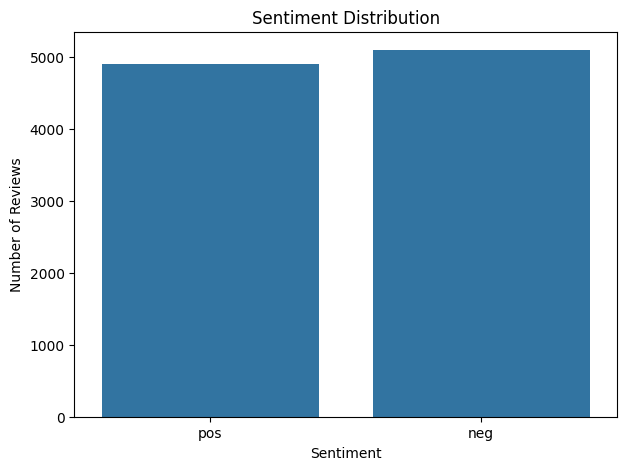

In [24]:
# Create a figure for the sentiment distribution
plt.figure(figsize=(7, 5))

# Create a bar chart showing the number of reviews in each class
sns.countplot(
    data=df,
    x='label'
)

# Add a title to the chart
plt.title('Sentiment Distribution')

# Add a label to the x axis
plt.xlabel('Sentiment')

# Add a label to the y axis
plt.ylabel('Number of Reviews')

# Display the chart
plt.show()

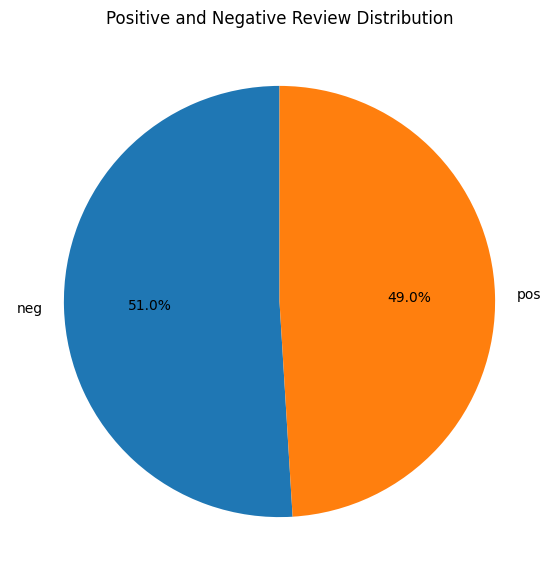

In [25]:
# Create a figure for the pie chart
plt.figure(figsize=(7, 7))

# Create a pie chart using the sentiment counts
plt.pie(
    sentiment_counts,
    labels=sentiment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

# Add a title
plt.title('Positive and Negative Review Distribution')

# Display the pie chart
plt.show()

In [26]:
# Select all positive reviews
positive_reviews = df[
    df['label'] == 'pos'
]['cleaned_review']

# Select all negative reviews
negative_reviews = df[
    df['label'] == 'neg'
]['cleaned_review']

# Display the number of reviews in each group
print("Number of Positive Reviews:", len(positive_reviews))
print("Number of Negative Reviews:", len(negative_reviews))

Number of Positive Reviews: 4903
Number of Negative Reviews: 5097


In [27]:
# Combine all cleaned positive reviews into one text string
positive_text = ' '.join(
    positive_reviews
)

# Display the first part of the combined text
print(positive_text[:500])

stuning even non gamer sound track beautiful paints senery mind well would recomend even people hate vid game music played game chrono cross games ever played best music backs away crude keyboarding takes fresher step grate guitars soulful orchestras would impress anyone cares listen best soundtrack ever anything reading lot reviews saying best game soundtrack figured write review disagree bit opinino yasunori mitsuda ultimate masterpiece music timeless listening years beauty simply refuses fade


In [30]:
# Combine all cleaned negative reviews into one text string
negative_text = ' '.join(
    negative_reviews
)

# Display the first part of the combined text
print(negative_text[:500])

buyer beware self published book want know read paragraphs star reviews must written ms haddon family friends perhaps imagine anyone reading whole thing spent evening book friend hysterics reading bits pieces one another definitely bad enough entered kind worst book contest believe amazon even sells kind thing maybe offer th grade term paper kill mockingbird book quite sure ms haddon never heard anyway unless mood send book someone joke stay far far away one worst complete waste time typographic


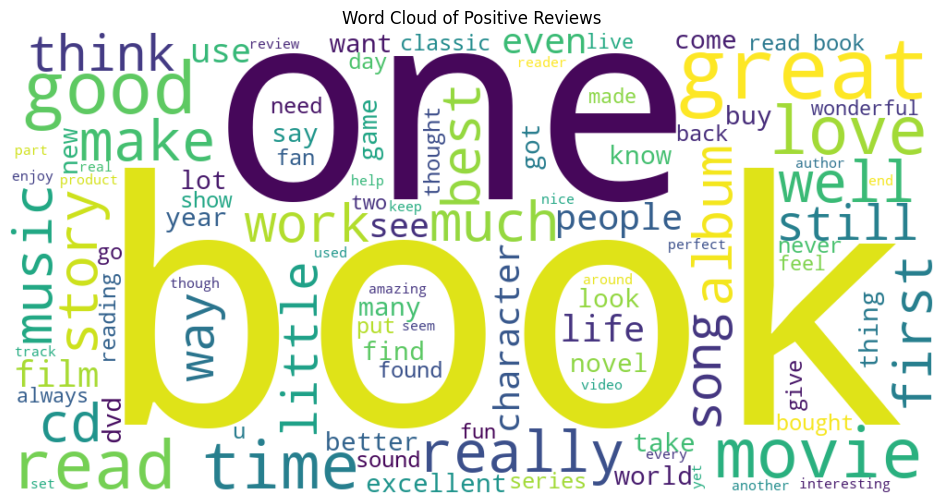

In [33]:
# Create a WordCloud object for positive reviews
positive_wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white',
    max_words=100
).generate(positive_text)

# Create a figure for the positive word cloud
plt.figure(figsize=(12, 6))

# Display the generated word cloud
plt.imshow(
    positive_wordcloud,
    interpolation='bilinear'
)

# Remove the axis because it is not needed for a word cloud
plt.axis('off')

# Add a title
plt.title('Word Cloud of Positive Reviews')

# Display the word cloud
plt.show()

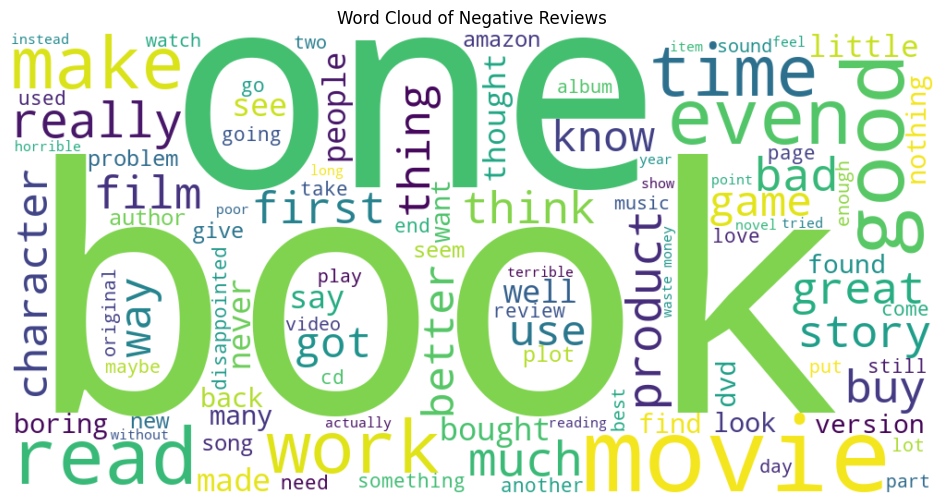

In [34]:
# Create a WordCloud object for negative reviews
negative_wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white',
    max_words=100
).generate(negative_text)

# Create a figure for the negative word cloud
plt.figure(figsize=(12, 6))

# Display the generated word cloud
plt.imshow(
    negative_wordcloud,
    interpolation='bilinear'
)

# Remove the axis
plt.axis('off')

# Add a title
plt.title('Word Cloud of Negative Reviews')

# Display the word cloud
plt.show()

In [35]:
# Combine all positive reviews and split them into individual words
positive_words = positive_text.split()

# Count how many times each positive word appears
positive_word_counts = Counter(
    positive_words
)

# Display the 20 most common positive words
print("Top 20 Positive Words:")
print(
    positive_word_counts.most_common(20)
)

Top 20 Positive Words:
[('book', 3390), ('great', 2135), ('one', 1916), ('good', 1667), ('read', 1605), ('like', 1290), ('movie', 1121), ('would', 956), ('well', 944), ('time', 924), ('love', 911), ('really', 832), ('best', 813), ('get', 805), ('story', 730), ('first', 724), ('much', 664), ('cd', 618), ('music', 577), ('also', 575)]


In [36]:
# Get the 20 most common positive words
top_positive_words = positive_word_counts.most_common(20)

# Convert the word frequency list into a DataFrame
positive_words_df = pd.DataFrame(
    top_positive_words,
    columns=['Word', 'Frequency']
)

# Display the DataFrame
positive_words_df

,Word,Frequency
0,book,3390
1,great,2135
2,one,1916
3,good,1667
4,read,1605
5,like,1290
6,movie,1121
7,would,956
8,well,944
9,time,924


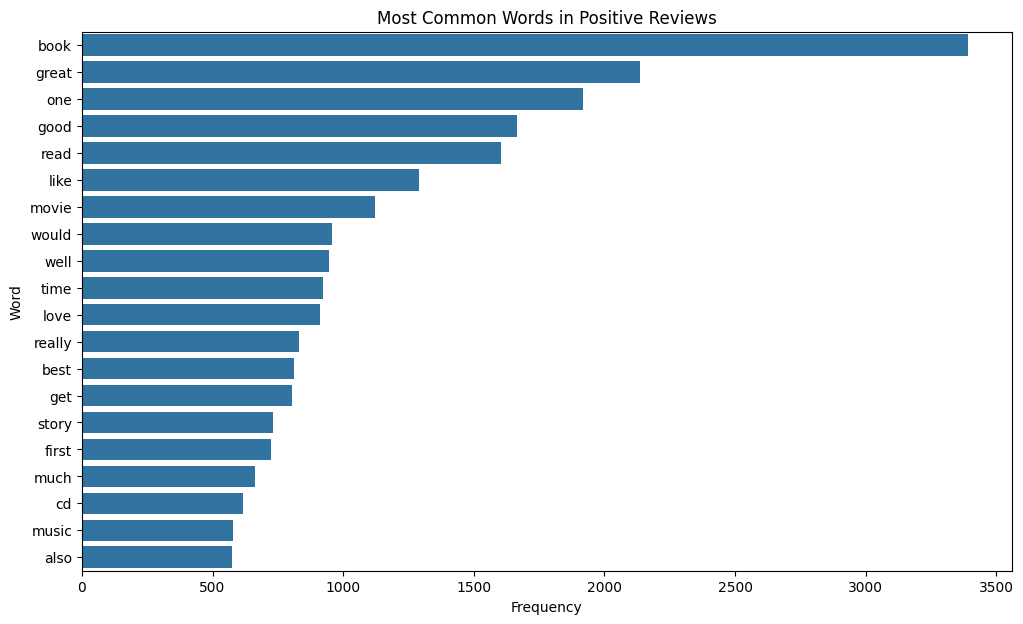

In [37]:
# Create a figure for the positive word frequency chart
plt.figure(figsize=(12, 7))

# Create a horizontal bar chart
sns.barplot(
    data=positive_words_df,
    x='Frequency',
    y='Word'
)

# Add a title
plt.title('Most Common Words in Positive Reviews')

# Add the x axis label
plt.xlabel('Frequency')

# Add the y axis label
plt.ylabel('Word')

# Display the chart
plt.show()

In [38]:
# Split the combined negative review text into individual words
negative_words = negative_text.split()

# Count the frequency of each negative word
negative_word_counts = Counter(
    negative_words
)

# Display the 20 most common negative words
print("Top 20 Negative Words:")
print(
    negative_word_counts.most_common(20)
)

Top 20 Negative Words:
[('book', 3277), ('one', 2100), ('like', 1569), ('movie', 1519), ('would', 1465), ('read', 1222), ('good', 1160), ('get', 1151), ('time', 1072), ('even', 910), ('buy', 835), ('really', 783), ('much', 782), ('money', 767), ('bad', 764), ('first', 760), ('better', 677), ('could', 667), ('great', 644), ('story', 641)]


In [39]:
# Get the 20 most common negative words
top_negative_words = negative_word_counts.most_common(20)

# Convert the word frequency list into a DataFrame
negative_words_df = pd.DataFrame(
    top_negative_words,
    columns=['Word', 'Frequency']
)

# Display the DataFrame
negative_words_df

,Word,Frequency
0,book,3277
1,one,2100
2,like,1569
3,movie,1519
4,would,1465
5,read,1222
6,good,1160
7,get,1151
8,time,1072
9,even,910


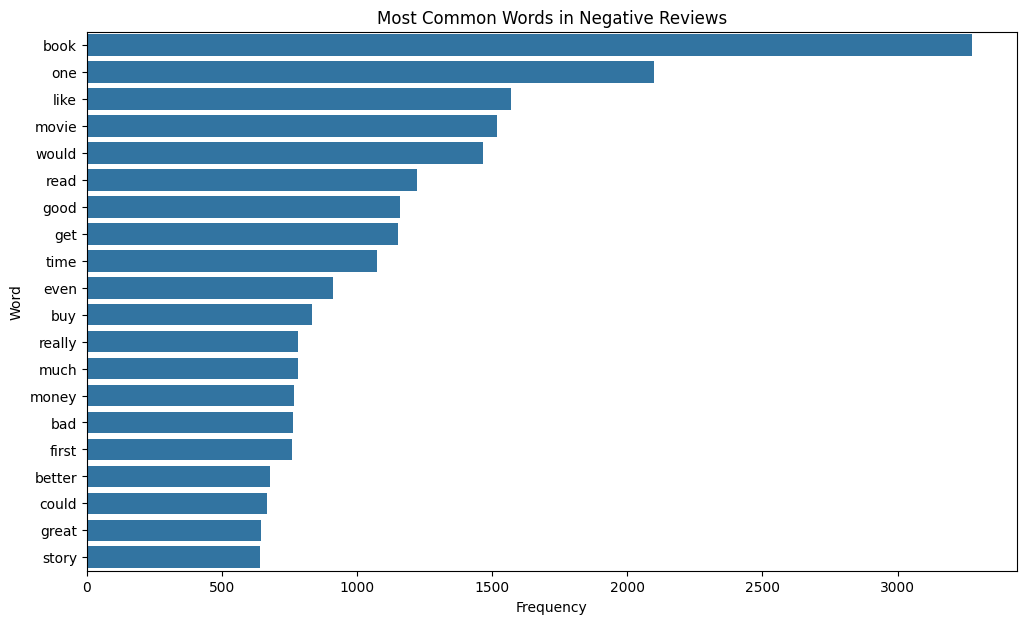

In [40]:
# Create a figure for the negative word frequency chart
plt.figure(figsize=(12, 7))

# Create a horizontal bar chart
sns.barplot(
    data=negative_words_df,
    x='Frequency',
    y='Word'
)

# Add a title
plt.title('Most Common Words in Negative Reviews')

# Add the x axis label
plt.xlabel('Frequency')

# Add the y axis label
plt.ylabel('Word')

# Display the chart
plt.show()

In [41]:
# Define additional words that may be common but less useful for sentiment interpretation
custom_stopwords = {
    'product',
    'movie',
    'book',
    'film',
    'one'
}

# Create a filtered list of positive words
filtered_positive_words = [
    word
    for word in positive_words
    if word not in custom_stopwords
]

# Count the filtered positive words
filtered_positive_counts = Counter(
    filtered_positive_words
)

# Display the most common filtered positive words
print("Most Common Positive Words After Additional Filtering:")
print(
    filtered_positive_counts.most_common(20)
)

Most Common Positive Words After Additional Filtering:
[('great', 2135), ('good', 1667), ('read', 1605), ('like', 1290), ('would', 956), ('well', 944), ('time', 924), ('love', 911), ('really', 832), ('best', 813), ('get', 805), ('story', 730), ('first', 724), ('much', 664), ('cd', 618), ('music', 577), ('also', 575), ('books', 543), ('little', 529), ('even', 520)]


In [42]:
# Create a filtered list of negative words
filtered_negative_words = [
    word
    for word in negative_words
    if word not in custom_stopwords
]

# Count the filtered negative words
filtered_negative_counts = Counter(
    filtered_negative_words
)

# Display the most common filtered negative words
print("Most Common Negative Words After Additional Filtering:")
print(
    filtered_negative_counts.most_common(20)
)

Most Common Negative Words After Additional Filtering:
[('like', 1569), ('would', 1465), ('read', 1222), ('good', 1160), ('get', 1151), ('time', 1072), ('even', 910), ('buy', 835), ('really', 783), ('much', 782), ('money', 767), ('bad', 764), ('first', 760), ('better', 677), ('could', 667), ('great', 644), ('story', 641), ('work', 624), ('never', 556), ('well', 556)]


Dataset Shape: (10000, 3)

Sentiment Distribution:
label
neg    5097
pos    4903
Name: count, dtype: int64

Sentiment Percentage:
label
neg    50.97
pos    49.03
Name: proportion, dtype: float64


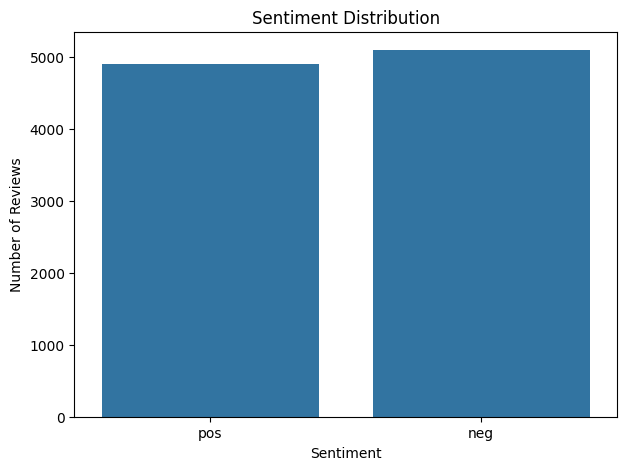

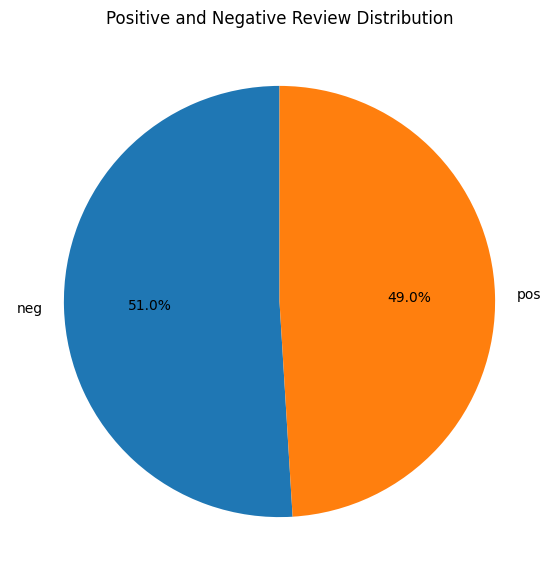

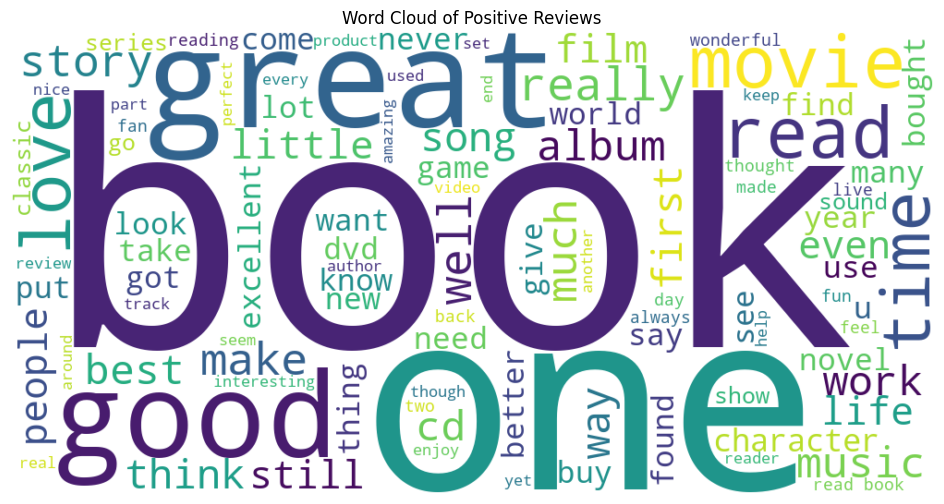

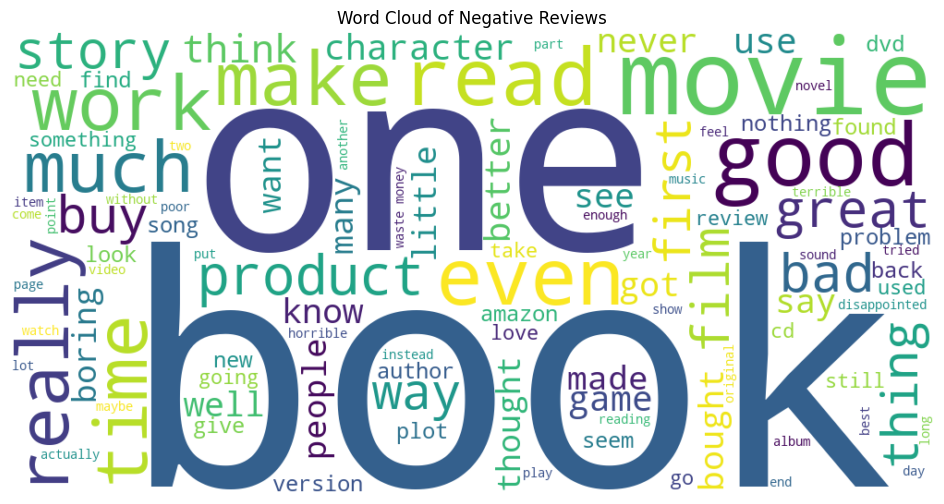


Most Common Positive Words:
      Word  Frequency
0     book       3390
1    great       2135
2      one       1916
3     good       1667
4     read       1605
5     like       1290
6    movie       1121
7    would        956
8     well        944
9     time        924
10    love        911
11  really        832
12    best        813
13     get        805
14   story        730
15   first        724
16    much        664
17      cd        618
18   music        577
19    also        575


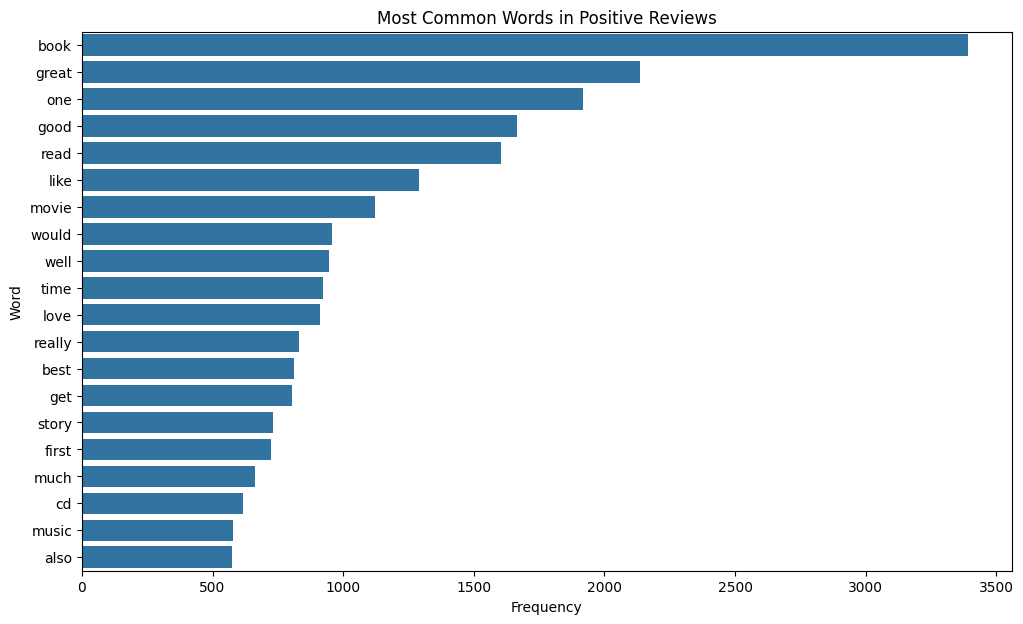


Most Common Negative Words:
      Word  Frequency
0     book       3277
1      one       2100
2     like       1569
3    movie       1519
4    would       1465
5     read       1222
6     good       1160
7      get       1151
8     time       1072
9     even        910
10     buy        835
11  really        783
12    much        782
13   money        767
14     bad        764
15   first        760
16  better        677
17   could        667
18   great        644
19   story        641


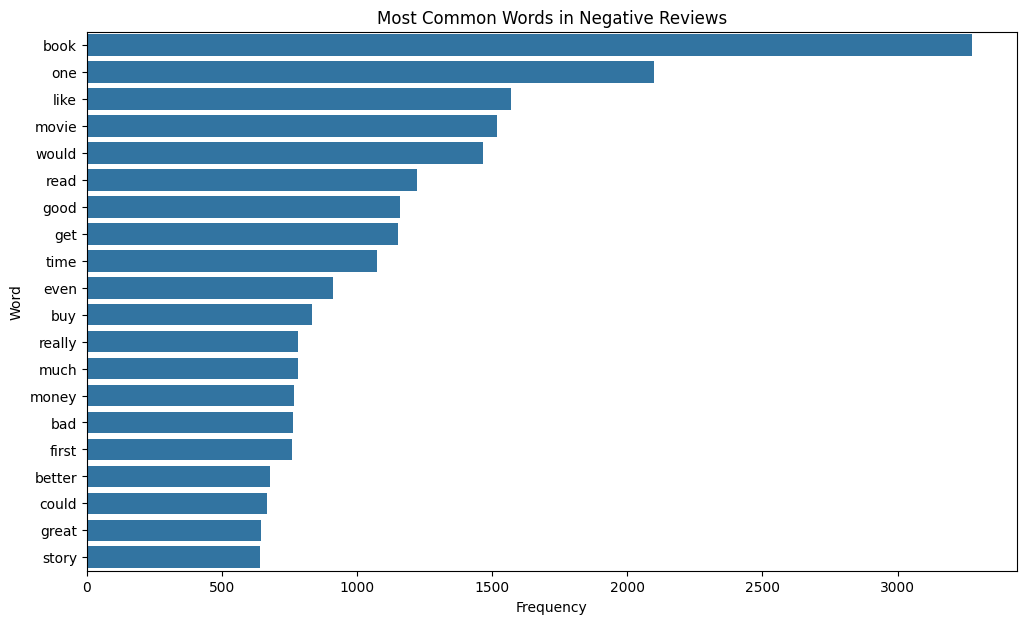

In [43]:
# Import required libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from wordcloud import WordCloud

# Check that the cleaned dataset is available
print("Dataset Shape:", df.shape)

# Display the sentiment distribution
sentiment_counts = df['label'].value_counts()

print("\nSentiment Distribution:")
print(sentiment_counts)

# Calculate sentiment percentages
sentiment_percentage = (
    df['label']
    .value_counts(normalize=True)
    * 100
)

print("\nSentiment Percentage:")
print(sentiment_percentage.round(2))

# Create sentiment distribution chart
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='label'
)

plt.title('Sentiment Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')
plt.show()

# Create sentiment pie chart
plt.figure(figsize=(7, 7))

plt.pie(
    sentiment_counts,
    labels=sentiment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Positive and Negative Review Distribution')
plt.show()

# Select positive reviews
positive_reviews = df[
    df['label'] == 'pos'
]['cleaned_review']

# Select negative reviews
negative_reviews = df[
    df['label'] == 'neg'
]['cleaned_review']

# Combine positive reviews
positive_text = ' '.join(
    positive_reviews
)

# Combine negative reviews
negative_text = ' '.join(
    negative_reviews
)

# Create positive word cloud
positive_wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white',
    max_words=100
).generate(positive_text)

plt.figure(figsize=(12, 6))

plt.imshow(
    positive_wordcloud,
    interpolation='bilinear'
)

plt.axis('off')
plt.title('Word Cloud of Positive Reviews')
plt.show()

# Create negative word cloud
negative_wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white',
    max_words=100
).generate(negative_text)

plt.figure(figsize=(12, 6))

plt.imshow(
    negative_wordcloud,
    interpolation='bilinear'
)

plt.axis('off')
plt.title('Word Cloud of Negative Reviews')
plt.show()

# Count positive words
positive_words = positive_text.split()

positive_word_counts = Counter(
    positive_words
)

# Get the 20 most common positive words
top_positive_words = positive_word_counts.most_common(20)

positive_words_df = pd.DataFrame(
    top_positive_words,
    columns=['Word', 'Frequency']
)

print("\nMost Common Positive Words:")
print(positive_words_df)

# Plot positive word frequencies
plt.figure(figsize=(12, 7))

sns.barplot(
    data=positive_words_df,
    x='Frequency',
    y='Word'
)

plt.title('Most Common Words in Positive Reviews')
plt.xlabel('Frequency')
plt.ylabel('Word')
plt.show()

# Count negative words
negative_words = negative_text.split()

negative_word_counts = Counter(
    negative_words
)

# Get the 20 most common negative words
top_negative_words = negative_word_counts.most_common(20)

negative_words_df = pd.DataFrame(
    top_negative_words,
    columns=['Word', 'Frequency']
)

print("\nMost Common Negative Words:")
print(negative_words_df)

# Plot negative word frequencies
plt.figure(figsize=(12, 7))

sns.barplot(
    data=negative_words_df,
    x='Frequency',
    y='Word'
)

plt.title('Most Common Words in Negative Reviews')
plt.xlabel('Frequency')
plt.ylabel('Word')
plt.show()

# Model Development

In [45]:
# Display the first five rows
print(df.head())

# Display the shape of the dataset
print("Dataset Shape:", df.shape)

# Display the column names
print("\nColumn Names:")
print(df.columns)

# Check the sentiment labels
print("\nSentiment Distribution:")
print(df['label'].value_counts())

  label                                             review  \
0   pos  Stuning even for the non-gamer: This sound tra...   
1   pos  The best soundtrack ever to anything.: I'm rea...   
2   pos  Amazing!: This soundtrack is my favorite music...   
3   pos  Excellent Soundtrack: I truly like this soundt...   
4   pos  Remember, Pull Your Jaw Off The Floor After He...   

                                      cleaned_review  
0  stuning even non gamer sound track beautiful p...  
1  best soundtrack ever anything reading lot revi...  
2  amazing soundtrack favorite music time hands i...  
3  excellent soundtrack truly like soundtrack enj...  
4  remember pull jaw floor hearing played game kn...  
Dataset Shape: (10000, 3)

Column Names:
Index(['label', 'review', 'cleaned_review'], dtype='object')

Sentiment Distribution:
label
neg    5097
pos    4903
Name: count, dtype: int64


In [46]:
# X contains the input feature
# Here, the input is the cleaned customer review
X = df['cleaned_review']

# y contains the target variable
# The target is the sentiment label
y = df['label']

# Display a few input reviews
print("Sample Reviews:")
print(X.head())

# Display corresponding labels
print("\nSample Labels:")
print(y.head())

Sample Reviews:
0    stuning even non gamer sound track beautiful p...
1    best soundtrack ever anything reading lot revi...
2    amazing soundtrack favorite music time hands i...
3    excellent soundtrack truly like soundtrack enj...
4    remember pull jaw floor hearing played game kn...
Name: cleaned_review, dtype: object

Sample Labels:
0    pos
1    pos
2    pos
3    pos
4    pos
Name: label, dtype: object


In [47]:
# Split the dataset into training and testing data
# 80% of the data will be used for training
# 20% of the data will be used for testing
# random_state ensures that we get the same split every time
# stratify ensures that positive and negative classes remain balanced
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the number of training samples
print("Training Samples:", len(X_train))

# Display the number of testing samples
print("Testing Samples:", len(X_test))

# Display sentiment distribution in training data
print("\nTraining Sentiment Distribution:")
print(y_train.value_counts())

# Display sentiment distribution in testing data
print("\nTesting Sentiment Distribution:")
print(y_test.value_counts())

Training Samples: 8000
Testing Samples: 2000

Training Sentiment Distribution:
label
neg    4078
pos    3922
Name: count, dtype: int64

Testing Sentiment Distribution:
label
neg    1019
pos     981
Name: count, dtype: int64


In [48]:
# Create a TF IDF vectorizer
tfidf = TfidfVectorizer(
    max_features=10000,     # Keep the 10,000 most important terms
    ngram_range=(1, 2),     # Use individual words and two word combinations
    min_df=2                # Ignore words appearing in only one document
)

# Learn the TF IDF vocabulary from training reviews
# and convert training reviews into numerical features
X_train_tfidf = tfidf.fit_transform(X_train)

# Convert the testing reviews using the same vocabulary
# We use transform instead of fit_transform to prevent data leakage
X_test_tfidf = tfidf.transform(X_test)

# Display the dimensions of the generated matrices
print("Training TF IDF Shape:", X_train_tfidf.shape)
print("Testing TF IDF Shape:", X_test_tfidf.shape)

Training TF IDF Shape: (8000, 10000)
Testing TF IDF Shape: (2000, 10000)


In [49]:
# Get all words/features learned by the TF IDF vectorizer
feature_names = tfidf.get_feature_names_out()

# Display the first 30 features
print("First 30 TF IDF Features:")
print(feature_names[:30])

# Display total number of features
print("\nTotal Number of Features:", len(feature_names))

First 30 TF IDF Features:
['aa' 'aa batteries' 'abandoned' 'abba' 'abilities' 'ability' 'able'
 'able find' 'able get' 'able play' 'able read' 'able use' 'able watch'
 'abroad' 'absent' 'absolute' 'absolutely' 'absolutely awful'
 'absolutely love' 'absolutely loved' 'absolutely nothing' 'absolutly'
 'absorbed' 'absorbing' 'absurd' 'abundant' 'abuse' 'abusive' 'ac'
 'ac adapter']

Total Number of Features: 10000


In [50]:
# Create the Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model using the TF IDF training features
logistic_model.fit(X_train_tfidf, y_train)

# Predict sentiment for the test reviews
y_pred_lr = logistic_model.predict(X_test_tfidf)

# Calculate accuracy
lr_accuracy = accuracy_score(y_test, y_pred_lr)

# Display the accuracy
print("Logistic Regression Accuracy:", lr_accuracy)

Logistic Regression Accuracy: 0.857


In [51]:
# Display detailed classification performance
print("Logistic Regression Classification Report:")
print(classification_report(y_test, y_pred_lr))

Logistic Regression Classification Report:
              precision    recall  f1-score   support

         neg       0.86      0.86      0.86      1019
         pos       0.86      0.85      0.85       981

    accuracy                           0.86      2000
   macro avg       0.86      0.86      0.86      2000
weighted avg       0.86      0.86      0.86      2000



In [52]:
# Generate the confusion matrix
cm_lr = confusion_matrix(y_test, y_pred_lr, labels=['neg', 'pos'])

# Display the confusion matrix
print("Logistic Regression Confusion Matrix:")
print(cm_lr)

Logistic Regression Confusion Matrix:
[[881 138]
 [148 833]]


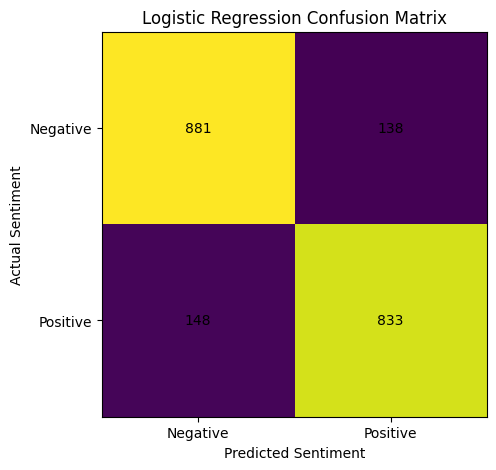

In [53]:
# Create a figure for the confusion matrix
plt.figure(figsize=(6, 5))

# Display the confusion matrix as an image
plt.imshow(cm_lr)

# Add axis labels
plt.xticks([0, 1], ['Negative', 'Positive'])
plt.yticks([0, 1], ['Negative', 'Positive'])

# Add axis titles
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')

# Add a title
plt.title('Logistic Regression Confusion Matrix')

# Display the values inside the matrix
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm_lr[i, j], ha='center', va='center')

plt.show()

In [54]:
# Create the Support Vector Machine model
svm_model = LinearSVC(
    random_state=42
)

# Train the SVM model using the TF IDF features
svm_model.fit(X_train_tfidf, y_train)

# Predict sentiment for the test data
y_pred_svm = svm_model.predict(X_test_tfidf)

# Calculate SVM accuracy
svm_accuracy = accuracy_score(y_test, y_pred_svm)

# Display SVM accuracy
print("SVM Accuracy:", svm_accuracy)

SVM Accuracy: 0.8445


In [55]:
# Display detailed SVM performance
print("SVM Classification Report:")
print(classification_report(y_test, y_pred_svm))

SVM Classification Report:
              precision    recall  f1-score   support

         neg       0.84      0.85      0.85      1019
         pos       0.85      0.83      0.84       981

    accuracy                           0.84      2000
   macro avg       0.84      0.84      0.84      2000
weighted avg       0.84      0.84      0.84      2000



In [56]:
# Generate confusion matrix for SVM
cm_svm = confusion_matrix(
    y_test,
    y_pred_svm,
    labels=['neg', 'pos']
)

# Display the confusion matrix
print("SVM Confusion Matrix:")
print(cm_svm)

SVM Confusion Matrix:
[[870 149]
 [162 819]]


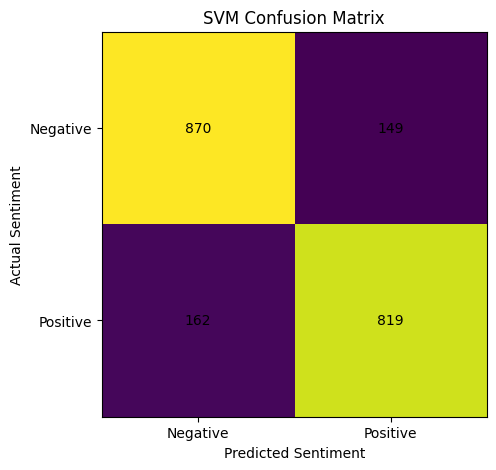

In [57]:
# Create a figure
plt.figure(figsize=(6, 5))

# Display the confusion matrix
plt.imshow(cm_svm)

# Set the labels
plt.xticks([0, 1], ['Negative', 'Positive'])
plt.yticks([0, 1], ['Negative', 'Positive'])

# Add axis labels
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')

# Add title
plt.title('SVM Confusion Matrix')

# Display the numerical values
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm_svm[i, j], ha='center', va='center')

plt.show()

In [58]:
# Create a DataFrame containing model performance
model_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'SVM'
    ],
    'Accuracy': [
        lr_accuracy,
        svm_accuracy
    ]
})

# Display the results
print(model_results)

                 Model  Accuracy
0  Logistic Regression    0.8570
1                  SVM    0.8445


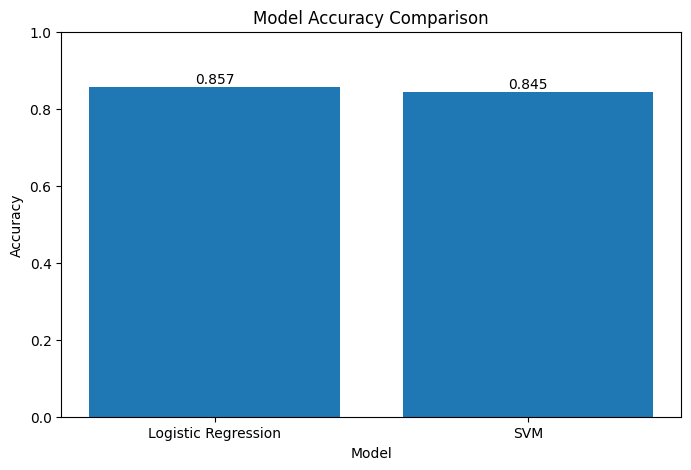

In [59]:
# Create a bar chart comparing model accuracy
plt.figure(figsize=(8, 5))

plt.bar(
    model_results['Model'],
    model_results['Accuracy']
)

# Add chart title and labels
plt.title('Model Accuracy Comparison')
plt.xlabel('Model')
plt.ylabel('Accuracy')

# Display accuracy values above each bar
for i, value in enumerate(model_results['Accuracy']):
    plt.text(
        i,
        value,
        f'{value:.3f}',
        ha='center',
        va='bottom'
    )

plt.ylim(0, 1)
plt.show()

# Validation

In [65]:
# Calculate accuracy for Logistic Regression
lr_accuracy = accuracy_score(y_test, y_pred_lr)

# Calculate precision for Logistic Regression
lr_precision = precision_score(
    y_test,
    y_pred_lr,
    pos_label='pos'
)

# Calculate recall for Logistic Regression
lr_recall = recall_score(
    y_test,
    y_pred_lr,
    pos_label='pos'
)

# Calculate F1 score for Logistic Regression
lr_f1 = f1_score(
    y_test,
    y_pred_lr,
    pos_label='pos'
)

# Display the results
print("Logistic Regression Validation Results")
print("--------------------------------------")

print("Accuracy :", round(lr_accuracy, 4))
print("Precision:", round(lr_precision, 4))
print("Recall   :", round(lr_recall, 4))
print("F1 Score :", round(lr_f1, 4))

Logistic Regression Validation Results
--------------------------------------
Accuracy : 0.857
Precision: 0.8579
Recall   : 0.8491
F1 Score : 0.8535


In [66]:
# Calculate accuracy for SVM
svm_accuracy = accuracy_score(y_test, y_pred_svm)

# Calculate precision for SVM
svm_precision = precision_score(
    y_test,
    y_pred_svm,
    pos_label='pos'
)

# Calculate recall for SVM
svm_recall = recall_score(
    y_test,
    y_pred_svm,
    pos_label='pos'
)

# Calculate F1 score for SVM
svm_f1 = f1_score(
    y_test,
    y_pred_svm,
    pos_label='pos'
)

# Display the results
print("SVM Validation Results")
print("----------------------")

print("Accuracy :", round(svm_accuracy, 4))
print("Precision:", round(svm_precision, 4))
print("Recall   :", round(svm_recall, 4))
print("F1 Score :", round(svm_f1, 4))

SVM Validation Results
----------------------
Accuracy : 0.8445
Precision: 0.8461
Recall   : 0.8349
F1 Score : 0.8404


In [67]:
# Create a DataFrame containing the validation metrics
validation_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'SVM'
    ],
    
    'Accuracy': [
        lr_accuracy,
        svm_accuracy
    ],
    
    'Precision': [
        lr_precision,
        svm_precision
    ],
    
    'Recall': [
        lr_recall,
        svm_recall
    ],
    
    'F1 Score': [
        lr_f1,
        svm_f1
    ]
})

# Display the validation results
print(validation_results)

                 Model  Accuracy  Precision    Recall  F1 Score
0  Logistic Regression    0.8570   0.857878  0.849134  0.853484
1                  SVM    0.8445   0.846074  0.834862  0.840431


In [68]:
# Create a copy of the results
validation_display = validation_results.copy()

# Round all metric values to four decimal places
validation_display[
    ['Accuracy', 'Precision', 'Recall', 'F1 Score']
] = validation_display[
    ['Accuracy', 'Precision', 'Recall', 'F1 Score']
].round(4)

# Display the formatted table
print(validation_display)

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression    0.8570     0.8579  0.8491    0.8535
1                  SVM    0.8445     0.8461  0.8349    0.8404


In [69]:
# Create a copy of the validation results
percentage_results = validation_results.copy()

# Convert metric values into percentages
percentage_results[
    ['Accuracy', 'Precision', 'Recall', 'F1 Score']
] = percentage_results[
    ['Accuracy', 'Precision', 'Recall', 'F1 Score']
] * 100

# Round the values
percentage_results[
    ['Accuracy', 'Precision', 'Recall', 'F1 Score']
] = percentage_results[
    ['Accuracy', 'Precision', 'Recall', 'F1 Score']
].round(2)

# Display the results
print(percentage_results)

                 Model  Accuracy  Precision  Recall  F1 Score
0  Logistic Regression     85.70      85.79   84.91     85.35
1                  SVM     84.45      84.61   83.49     84.04


In [70]:
# Generate a detailed classification report
lr_report = classification_report(
    y_test,
    y_pred_lr
)

# Display the report
print("Logistic Regression Classification Report")
print(lr_report)

Logistic Regression Classification Report
              precision    recall  f1-score   support

         neg       0.86      0.86      0.86      1019
         pos       0.86      0.85      0.85       981

    accuracy                           0.86      2000
   macro avg       0.86      0.86      0.86      2000
weighted avg       0.86      0.86      0.86      2000



In [71]:
# Generate a detailed classification report for SVM
svm_report = classification_report(
    y_test,
    y_pred_svm
)

# Display the report
print("SVM Classification Report")
print(svm_report)

SVM Classification Report
              precision    recall  f1-score   support

         neg       0.84      0.85      0.85      1019
         pos       0.85      0.83      0.84       981

    accuracy                           0.84      2000
   macro avg       0.84      0.84      0.84      2000
weighted avg       0.84      0.84      0.84      2000



In [72]:
# Calculate the confusion matrix
cm_lr = confusion_matrix(
    y_test,
    y_pred_lr,
    labels=['neg', 'pos']
)

# Display the confusion matrix
print("Logistic Regression Confusion Matrix")
print(cm_lr)

Logistic Regression Confusion Matrix
[[881 138]
 [148 833]]


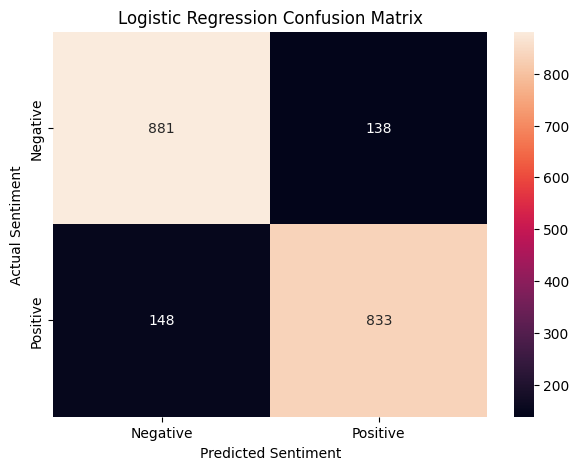

In [73]:
# Create a figure
plt.figure(figsize=(7, 5))

# Create a heatmap for the confusion matrix
sns.heatmap(
    cm_lr,
    annot=True,
    fmt='d',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)

# Add labels
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')

# Add title
plt.title('Logistic Regression Confusion Matrix')

# Display the plot
plt.show()

In [74]:
# Calculate the confusion matrix for SVM
cm_svm = confusion_matrix(
    y_test,
    y_pred_svm,
    labels=['neg', 'pos']
)

# Display the confusion matrix
print("SVM Confusion Matrix")
print(cm_svm)

SVM Confusion Matrix
[[870 149]
 [162 819]]


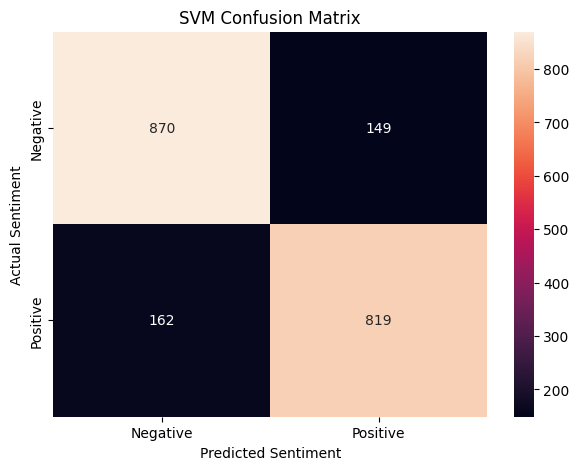

In [75]:
# Create a figure
plt.figure(figsize=(7, 5))

# Create a heatmap
sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    xticklabels=['Negative', 'Positive'],
    yticklabels=['Negative', 'Positive']
)

# Add labels
plt.xlabel('Predicted Sentiment')
plt.ylabel('Actual Sentiment')

# Add title
plt.title('SVM Confusion Matrix')

# Display the plot
plt.show()

In [76]:
# Create Stratified K Fold cross validation
# The dataset will be divided into 5 folds
# Each fold maintains the positive and negative class distribution
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [77]:
# Perform 5 fold cross validation for Logistic Regression
lr_cv_accuracy = cross_val_score(
    logistic_model,
    X_train_tfidf,
    y_train,
    cv=cv,
    scoring='accuracy'
)

# Display accuracy obtained from each fold
print("Logistic Regression Accuracy for Each Fold:")
print(lr_cv_accuracy)

# Calculate the average accuracy
print("\nAverage Cross Validation Accuracy:")
print(round(lr_cv_accuracy.mean(), 4))

# Calculate the standard deviation
print("\nStandard Deviation:")
print(round(lr_cv_accuracy.std(), 4))

Logistic Regression Accuracy for Each Fold:
[0.85125  0.864375 0.86625  0.86625  0.873125]

Average Cross Validation Accuracy:
0.8642

Standard Deviation:
0.0072


In [78]:
# Perform 5 fold cross validation for SVM
svm_cv_accuracy = cross_val_score(
    svm_model,
    X_train_tfidf,
    y_train,
    cv=cv,
    scoring='accuracy'
)

# Display accuracy for each fold
print("SVM Accuracy for Each Fold:")
print(svm_cv_accuracy)

# Calculate average accuracy
print("\nAverage Cross Validation Accuracy:")
print(round(svm_cv_accuracy.mean(), 4))

# Calculate standard deviation
print("\nStandard Deviation:")
print(round(svm_cv_accuracy.std(), 4))

SVM Accuracy for Each Fold:
[0.84125  0.8525   0.8575   0.864375 0.864375]

Average Cross Validation Accuracy:
0.856

Standard Deviation:
0.0086


In [79]:
# Perform 5 fold cross validation using F1 score
lr_cv_f1 = cross_val_score(
    logistic_model,
    X_train_tfidf,
    y_train,
    cv=cv,
    scoring='f1_weighted'
)

# Display F1 score for each fold
print("Logistic Regression F1 Scores:")
print(lr_cv_f1)

# Calculate average F1 score
print("\nAverage Logistic Regression F1 Score:")
print(round(lr_cv_f1.mean(), 4))

# Calculate standard deviation
print("\nStandard Deviation:")
print(round(lr_cv_f1.std(), 4))

Logistic Regression F1 Scores:
[0.85125604 0.86436975 0.86625585 0.86620984 0.87311583]

Average Logistic Regression F1 Score:
0.8642

Standard Deviation:
0.0071


In [80]:
# Perform 5 fold cross validation using F1 score
svm_cv_f1 = cross_val_score(
    svm_model,
    X_train_tfidf,
    y_train,
    cv=cv,
    scoring='f1_weighted'
)

# Display F1 scores for each fold
print("SVM F1 Scores:")
print(svm_cv_f1)

# Calculate average F1 score
print("\nAverage SVM F1 Score:")
print(round(svm_cv_f1.mean(), 4))

# Calculate standard deviation
print("\nStandard Deviation:")
print(round(svm_cv_f1.std(), 4))

SVM F1 Scores:
[0.8412624  0.85247694 0.85751403 0.86431597 0.86438809]

Average SVM F1 Score:
0.856

Standard Deviation:
0.0086


In [81]:
# Create a DataFrame containing cross validation results
cv_results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'SVM'
    ],
    
    'Average Accuracy': [
        lr_cv_accuracy.mean(),
        svm_cv_accuracy.mean()
    ],
    
    'Accuracy Std': [
        lr_cv_accuracy.std(),
        svm_cv_accuracy.std()
    ],
    
    'Average F1 Score': [
        lr_cv_f1.mean(),
        svm_cv_f1.mean()
    ],
    
    'F1 Std': [
        lr_cv_f1.std(),
        svm_cv_f1.std()
    ]
})

# Round the values
cv_results[
    [
        'Average Accuracy',
        'Accuracy Std',
        'Average F1 Score',
        'F1 Std'
    ]
] = cv_results[
    [
        'Average Accuracy',
        'Accuracy Std',
        'Average F1 Score',
        'F1 Std'
    ]
].round(4)

# Display the cross validation results
print(cv_results)

                 Model  Average Accuracy  Accuracy Std  Average F1 Score  \
0  Logistic Regression            0.8642        0.0072            0.8642   
1                  SVM            0.8560        0.0086            0.8560   

   F1 Std  
0  0.0071  
1  0.0086  


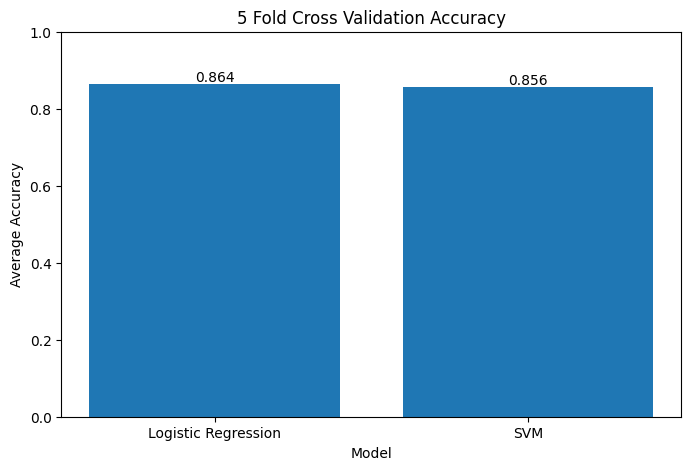

In [82]:
# Create a figure
plt.figure(figsize=(8, 5))

# Create a bar chart for cross validation accuracy
plt.bar(
    cv_results['Model'],
    cv_results['Average Accuracy']
)

# Add title
plt.title('5 Fold Cross Validation Accuracy')

# Add axis labels
plt.xlabel('Model')
plt.ylabel('Average Accuracy')

# Display the accuracy value above each bar
for i, value in enumerate(cv_results['Average Accuracy']):
    plt.text(
        i,
        value,
        f'{value:.3f}',
        ha='center',
        va='bottom'
    )

# Set y axis range
plt.ylim(0, 1)

# Display the chart
plt.show()

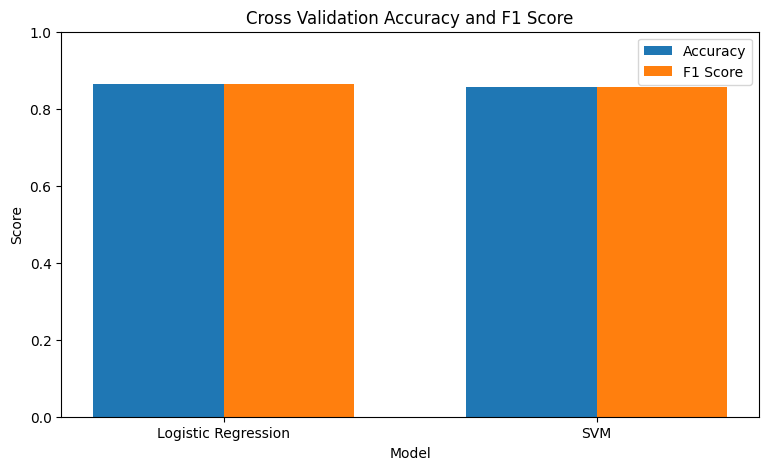

In [83]:
# Create the positions of the models on the x axis
x = range(len(cv_results))

# Set the width of each bar
width = 0.35

# Create a figure
plt.figure(figsize=(9, 5))

# Plot average accuracy
plt.bar(
    [i - width / 2 for i in x],
    cv_results['Average Accuracy'],
    width=width,
    label='Accuracy'
)

# Plot average F1 score
plt.bar(
    [i + width / 2 for i in x],
    cv_results['Average F1 Score'],
    width=width,
    label='F1 Score'
)

# Set model names on x axis
plt.xticks(
    list(x),
    cv_results['Model']
)

# Add title and labels
plt.title('Cross Validation Accuracy and F1 Score')
plt.xlabel('Model')
plt.ylabel('Score')

# Display legend
plt.legend()

# Set y axis
plt.ylim(0, 1)

# Display graph
plt.show()